In [1]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

In [3]:
def read(path):
    #read images
    img = cv2.imread(path)
    plt.imshow(img)
    plt.title("original_image")
    #plt.savefig(save_path+'/original_image.png')
    plt.show()
    return img

def region_of_interest(image):
    zero_mask = np.zeros_like(image)
    no_of_channels = image.shape[2]
    zero_mask_color = (255,) * no_of_channels
    #polygons
    height = image.shape[0]
    width = image.shape[1]
    coor = [(0, height),(width / 2, height / 2),(width, height)]
    polygon = np.array([coor], np.int32)
    cv2.fillPoly(zero_mask, polygon, zero_mask_color)
    proposed_region = cv2.bitwise_and(image, zero_mask)
    plt.imshow(proposed_region)
    plt.title("region_of_interest")
    #plt.savefig(save_path + '/ region_of_interest.png')
    plt.show()
    return proposed_region

def rgb_to_hsv(proposed_roi):
    #rgb to hsv
    hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    plt.imshow(hsv_img)
    plt.title("hsv_image")
    #plt.savefig(save_path + '/ hsv_image.png')
    plt.show()
    return hsv_img

def binar(roi_rgb):
    #create binary image
    binary_img = np.full((rgb_img.shape[0], rgb_img.shape[1]), fill_value=255)
    plt.imshow(binary_img, cmap='gray')
    plt.title("binary_image")
    #plt.savefig(save_path + '/ binary_image.png')
    plt.show()
    return binary_img

def gaussian_filter(hsv_img):
    #apply gaussian filter
    blurred_img = cv2.GaussianBlur(hsv_img, ksize=(5,5), sigmaX = 0.1)
    plt.imshow(blurred_img)
    plt.title("blurred_hsv_image")
    #plt.savefig(save_path + '/ blurred_hsv_image.png')
    plt.show()
    return blurred_img

#get yellow and white lines
def extract_yellow_white(hsv_img, binary_img, rgb_img):
  for i, pixels in enumerate(hsv_img):
    for j, val in enumerate(pixels):
      if (((val[0]>10 and val[0]<100) and (val[2]>=190)) or (val[1]<=65 and val[2]>=140)):
        pass
      else:
        binary_img[i][j] = 0
        hsv_img[i][j] = [0,0,0]
        
  for x, b in enumerate(binary_img):
    for y ,z in enumerate(b):
      if z == 0:
        rgb_img[x][y] = [0,0,0]
        
  plt.imshow(binary_img, cmap='gray')
  plt.title("extracted yellow and white lines(3)")
  #plt.savefig(save_path + '/extracted yellow and white lines(3).png')
  plt.show()
  return binary_img, hsv_img, rgb_img

def rgb_to_grayscale(img):
    imgGray = np.round(np.mean(img, -1))
    plt.imshow(imgGray , cmap='gray')
    plt.title("grayscale_image")
    plt.savefig(save_path + '/grayscale.png')
    plt.show()
    return imgGray

def canny(rgb_img):
    #I = cv2.imread(path)
    gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_BGR2GRAY)
    #binary = binar(I)
    edges = cv2.Canny(gray_img, 100, 300)
    plt.imshow(edges, cmap='gray') 
    for x, b in enumerate(edges):
        for y ,z in enumerate(b):
            if z == 0:
                binary_img[x][y] = 1
            else:
                binary_img[x][y] = 0
    plt.imshow(binary_img, cmap='gray')
    plt.title("Final Edges")
    #plt.savefig(save_path + '/Final_edges.png')
    plt.show()
    return binary_img
 
def hough_transform(edges):             
    theta = np.pi/180        
    minLineLength = 40  
    threshold = 100   
    maxLineGap = 40 
    rho = 2     
    return cv2.HoughLinesP(edges, rho = rho, theta = theta, threshold = threshold,
                           minLineLength = minLineLength, maxLineGap = maxLineGap) 
    

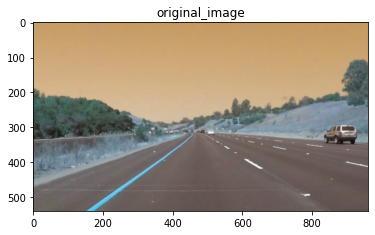

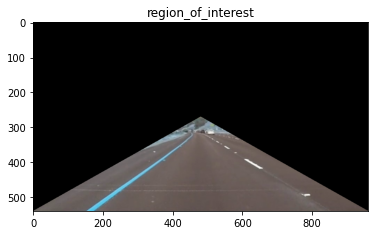

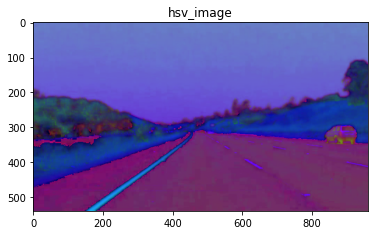

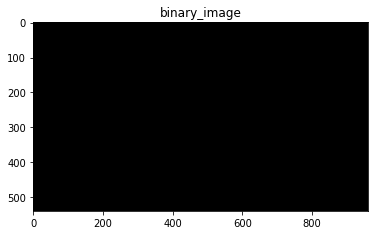

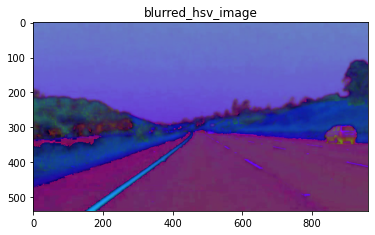

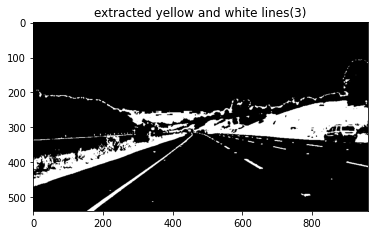

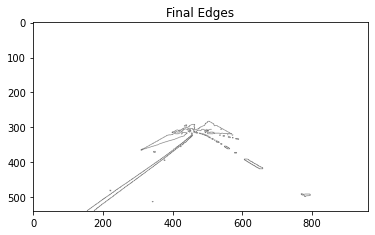

In [4]:
#image path
path = "/content/gdrive/MyDrive/3rd_semester/Computer Vision/assignments/assignment_4/code/images/test7.jpg"
#save_path = 'results/test25'
#os.makedirs(f'{save_path}', exist_ok=True)
#reads_images
img = read(path)
#regions of interest
rgb_img = region_of_interest(img)
#hsv_conversion
hsv_img = rgb_to_hsv(rgb_img)
#binary_image
binary_img = binar(rgb_img)
#blurr hsv_img
blur_hsv_img = gaussian_filter(hsv_img)
#EXTRACT yellow and white lines
binary_img, hsv_img, rgb_img = extract_yellow_white(blur_hsv_img, binary_img, rgb_img)
#apply canny edge detection
binary_img = canny(rgb_img)